<a href="https://colab.research.google.com/github/tejushkumarsharma0880-code/Heart-Failure-Records-EDA/blob/main/Heart_Failure_Records_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Heart_Failure_Details.csv")

# clean column names: lowercase, underscores, rename death -> death_event
df.columns = [c.strip().lower().replace(".", "").replace(" ", "_") for c in df.columns]
df = df.rename(columns={"death": "death_event"})
print(df.columns.tolist())

['s_no', 'age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_bp', 'platelets', 'serum_creatinine', 'sex', 'smoking', 'death_event']


# ============ DATA PREPROCESSING ============


In [22]:
import numpy as np
import pandas as pd

df = pd.read_csv("Heart_Failure_Details.csv")
print("Raw shape:", df.shape)

Raw shape: (299, 12)


# ---- 1. Standardise column names ----

In [23]:
df.columns = [c.strip().lower().replace(".", "").replace(" ", "_") for c in df.columns]
df = df.rename(columns={"death": "death_event"})

# ---- 2. Drop irrelevant column (row index, not data) ----

In [24]:
df = df.drop(columns=["s_no"])

# ---- 3. Missing values ----

In [25]:
print("Missing values before:", df.isnull().sum().sum())
num_cols = df.select_dtypes(include=np.number).columns
for c in num_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].median())   # median imputation (only runs if needed)
print("Missing values after:", df.isnull().sum().sum())

Missing values before: 0
Missing values after: 0


# ---- 4. Duplicates ----

In [26]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after:", df.duplicated().sum())


Duplicates before: 0
Duplicates after: 0


# ---- 5. Fix data types ----

In [27]:
int_cols = ["age", "platelets", "creatinine_phosphokinase", "ejection_fraction"]
df[int_cols] = df[int_cols].round().astype(int)
binary_cols = ["anaemia", "diabetes", "high_bp", "sex", "smoking", "death_event"]
df[binary_cols] = df[binary_cols].astype(int)

# ---- 6. Validity checks (impossible values) ----

In [28]:
assert df["age"].between(0, 120).all(), "Invalid age found"
assert df["ejection_fraction"].between(1, 100).all(), "Invalid ejection fraction"
for c in binary_cols:
    assert set(df[c].unique()) <= {0, 1}, f"{c} has values other than 0/1"
print("Negative values:", (df.select_dtypes(include=np.number) < 0).sum().sum())

Negative values: 0


# ---- 7. Outlier detection (IQR rule, NumPy) ----

In [29]:
for c in ["creatinine_phosphokinase", "platelets", "serum_creatinine", "ejection_fraction"]:
    arr = df[c].to_numpy()
    q1, q3 = np.percentile(arr, [25, 75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df[f"{c}_outlier"] = (arr < lower) | (arr > upper)   # True/False flag
    df[f"{c}_capped"] = np.clip(arr, lower, upper)       # winsorised copy
    print(f"{c}: {df[f'{c}_outlier'].sum()} outliers (range {lower:.2f} to {upper:.2f})")

creatinine_phosphokinase: 29 outliers (range -581.75 to 1280.25)
platelets: 21 outliers (range 76000.00 to 440000.00)
serum_creatinine: 29 outliers (range 0.15 to 2.15)
ejection_fraction: 2 outliers (range 7.50 to 67.50)


# ---- 8. Feature engineering / readable labels ----

In [30]:
df["age_group"] = pd.cut(df["age"], bins=[40, 50, 60, 70, 80, 100],
                         labels=["40-49", "50-59", "60-69", "70-79", "80+"], right=False)
df["death_label"] = df["death_event"].map({0: "No death", 1: "Death"})
df["sex_label"] = df["sex"].map({0: "Female", 1: "Male"})
for c in ["anaemia", "diabetes", "high_bp", "smoking"]:
    df[f"{c}_label"] = df[c].map({0: "No", 1: "Yes"})

# ---- 9. Save cleaned data ----

In [31]:
df.to_csv("Heart_Failure_Cleaned.csv", index=False)
print("Cleaned shape:", df.shape)
display(df.head())

Cleaned shape: (299, 26)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_bp,platelets,serum_creatinine,sex,smoking,...,serum_creatinine_capped,ejection_fraction_outlier,ejection_fraction_capped,age_group,death_label,sex_label,anaemia_label,diabetes_label,high_bp_label,smoking_label
0,75,0,582,0,20,1,265000,1.9,1,0,...,1.90,False,20.0,70-79,Death,Male,No,No,Yes,No
1,55,0,7861,0,38,0,263358,1.1,1,0,...,1.10,False,38.0,50-59,Death,Male,No,No,No,No
2,65,0,146,0,20,0,162000,1.3,1,1,...,1.30,False,20.0,60-69,Death,Male,No,No,No,Yes
3,50,1,111,0,20,0,210000,1.9,1,0,...,1.90,False,20.0,50-59,Death,Male,Yes,No,No,No
4,65,1,160,1,20,0,327000,2.7,0,0,...,2.15,False,20.0,60-69,Death,Female,Yes,Yes,No,No


Step 1: Basic inspection

In [32]:
display(df.head())
display(df.tail())
print("Shape:", df.shape)
df.info()
display(df.describe())

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_bp,platelets,serum_creatinine,sex,smoking,...,serum_creatinine_capped,ejection_fraction_outlier,ejection_fraction_capped,age_group,death_label,sex_label,anaemia_label,diabetes_label,high_bp_label,smoking_label
0,75,0,582,0,20,1,265000,1.9,1,0,...,1.90,False,20.0,70-79,Death,Male,No,No,Yes,No
1,55,0,7861,0,38,0,263358,1.1,1,0,...,1.10,False,38.0,50-59,Death,Male,No,No,No,No
2,65,0,146,0,20,0,162000,1.3,1,1,...,1.30,False,20.0,60-69,Death,Male,No,No,No,Yes
3,50,1,111,0,20,0,210000,1.9,1,0,...,1.90,False,20.0,50-59,Death,Male,Yes,No,No,No
4,65,1,160,1,20,0,327000,2.7,0,0,...,2.15,False,20.0,60-69,Death,Female,Yes,Yes,No,No


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_bp,platelets,serum_creatinine,sex,smoking,...,serum_creatinine_capped,ejection_fraction_outlier,ejection_fraction_capped,age_group,death_label,sex_label,anaemia_label,diabetes_label,high_bp_label,smoking_label
294,62,0,61,1,38,1,155000,1.1,1,1,...,1.1,False,38.0,60-69,No death,Male,No,Yes,Yes,Yes
295,55,0,1820,0,38,0,270000,1.2,0,0,...,1.2,False,38.0,50-59,No death,Female,No,No,No,No
296,45,0,2060,1,60,0,742000,0.8,0,0,...,0.8,False,60.0,40-49,No death,Female,No,Yes,No,No
297,45,0,2413,0,38,0,140000,1.4,1,1,...,1.4,False,38.0,40-49,No death,Male,No,No,No,Yes
298,50,0,196,0,45,0,395000,1.6,1,1,...,1.6,False,45.0,50-59,No death,Male,No,No,No,Yes


Shape: (299, 26)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype   
---  ------                            --------------  -----   
 0   age                               299 non-null    int64   
 1   anaemia                           299 non-null    int64   
 2   creatinine_phosphokinase          299 non-null    int64   
 3   diabetes                          299 non-null    int64   
 4   ejection_fraction                 299 non-null    int64   
 5   high_bp                           299 non-null    int64   
 6   platelets                         299 non-null    int64   
 7   serum_creatinine                  299 non-null    float64 
 8   sex                               299 non-null    int64   
 9   smoking                           299 non-null    int64   
 10  death_event                       299 non-null    int64   
 11  creatinine_phosphokinase_outlier  299 non

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_bp,platelets,serum_creatinine,sex,smoking,death_event,creatinine_phosphokinase_capped,platelets_capped,serum_creatinine_capped,ejection_fraction_capped
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.00000,299.00000,299.000000,299.000000,299.000000,299.000000
mean,60.836120,0.431438,581.839465,0.418060,38.083612,0.351171,263358.026756,1.39388,0.648829,0.32107,0.32107,424.214883,259163.712375,1.234515,38.033445
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,0.478136,0.46767,0.46767,385.449328,81478.304239,0.440098,11.685643
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,0.000000,0.00000,0.00000,23.000000,76000.000000,0.500000,14.000000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,0.000000,0.00000,0.00000,116.500000,212500.000000,0.900000,30.000000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,1.000000,0.00000,0.00000,250.000000,262000.000000,1.100000,38.000000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,1.000000,1.00000,1.00000,582.000000,303500.000000,1.400000,45.000000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,1.000000,1.00000,1.00000,1280.250000,440000.000000,2.150000,67.500000


#Q1: What is the age distribution?

Mean age: 60.836120401337794
Std dev : 11.894808790954748
Age percentiles (25/50/75): [51. 60. 70.]
age_group
40-49    47
50-59    82
60-69    93
70-79    52
80+      25
Name: count, dtype: int64


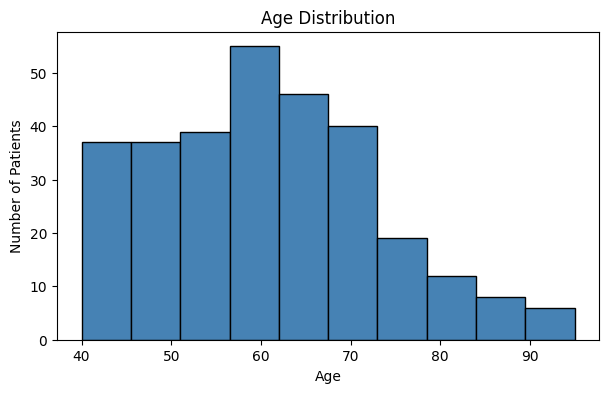

In [33]:
age = df["age"].to_numpy()                      # NumPy array
print("Mean age:", np.mean(age))
print("Std dev :", np.std(age, ddof=1))
print("Age percentiles (25/50/75):", np.percentile(age, [25, 50, 75]))

# group ages into bins and count
bins = [40, 50, 60, 70, 80, 100]
labels = ["40-49", "50-59", "60-69", "70-79", "80+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels, right=False)
print(df["age_group"].value_counts().sort_index())

# Chart 2: age histogram
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=10, color="steelblue", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

# Q2: Count records by death_event.

death_event
0    203
1     96
Name: count, dtype: int64
death_event
0    67.89
1    32.11
Name: proportion, dtype: float64


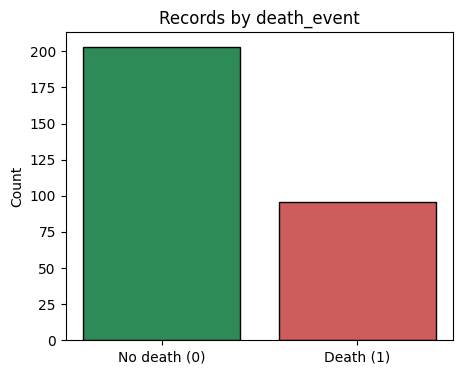

In [34]:
counts = df["death_event"].value_counts()
print(counts)
print((df["death_event"].value_counts(normalize=True) * 100).round(2))

# Chart 1: death_event bar chart
plt.figure(figsize=(5, 4))
plt.bar(["No death (0)", "Death (1)"], counts.sort_index().values,
        color=["seagreen", "indianred"], edgecolor="black")
plt.title("Records by death_event")
plt.ylabel("Count")
plt.show()

# Q3: Find mean, median, minimum and maximum for age, ejection_fraction and serum_creatinine.

In [35]:
cols = ["age", "ejection_fraction", "serum_creatinine"]
rows = []
for c in cols:
    arr = df[c].to_numpy()
    rows.append([c, np.mean(arr), np.median(arr), np.min(arr), np.max(arr)])

summary = pd.DataFrame(rows, columns=["column", "mean", "median", "min", "max"]).round(2)
display(summary)

,column,mean,median,min,max
0,age,60.84,60.0,40.0,95.0
1,ejection_fraction,38.08,38.0,14.0,80.0
2,serum_creatinine,1.39,1.1,0.5,9.4


# Q4: Compare average ejection_fraction and serum_creatinine across death_event groups.

In [36]:
group_means = df.groupby("death_event")[["ejection_fraction", "serum_creatinine"]].mean().round(2)
display(group_means)

# optional: sorted/filtered views (shows Pandas filtering + sorting)
died = df[df["death_event"] == 1]
survived = df[df["death_event"] == 0]
print("Died:", len(died), "| Survived:", len(survived))
display(df.sort_values("serum_creatinine", ascending=False).head(5))

,ejection_fraction,serum_creatinine
death_event,,
0,40.27,1.18
1,33.47,1.84


Died: 96 | Survived: 203


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_bp,platelets,serum_creatinine,sex,smoking,...,serum_creatinine_capped,ejection_fraction_outlier,ejection_fraction_capped,age_group,death_label,sex_label,anaemia_label,diabetes_label,high_bp_label,smoking_label
9,80,1,123,0,35,1,388000,9.4,1,1,...,2.15,False,35.0,80+,Death,Male,Yes,No,Yes,Yes
217,54,1,427,0,70,1,151000,9.0,0,0,...,2.15,True,67.5,50-59,Death,Female,Yes,No,Yes,No
52,60,0,3964,1,62,0,263358,6.8,0,0,...,2.15,False,62.0,60-69,Death,Female,No,Yes,No,No
131,60,1,1082,1,45,0,250000,6.1,1,0,...,2.15,False,45.0,60-69,No death,Male,Yes,Yes,No,No
28,58,1,60,0,38,0,153000,5.8,1,0,...,2.15,False,38.0,50-59,Death,Male,Yes,No,No,No


# Q5:  Count records with and without diabetes, high blood pressure and anaemia.

In [37]:
for c in ["diabetes", "high_bp", "anaemia"]:
    print(f"--- {c} ---")
    print(df[c].value_counts().rename({0: "Without", 1: "With"}))
    print()

--- diabetes ---
diabetes
Without    174
With       125
Name: count, dtype: int64

--- high_bp ---
high_bp
Without    194
With       105
Name: count, dtype: int64

--- anaemia ---
anaemia
Without    170
With       129
Name: count, dtype: int64



# Q6: Check missing values and duplicates. Use NumPy and Pandas descriptive EDA only

In [38]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
age                                 0
anaemia                             0
creatinine_phosphokinase            0
diabetes                            0
ejection_fraction                   0
high_bp                             0
platelets                           0
serum_creatinine                    0
sex                                 0
smoking                             0
death_event                         0
creatinine_phosphokinase_outlier    0
creatinine_phosphokinase_capped     0
platelets_outlier                   0
platelets_capped                    0
serum_creatinine_outlier            0
serum_creatinine_capped             0
ejection_fraction_outlier           0
ejection_fraction_capped            0
age_group                           0
death_label                         0
sex_label                           0
anaemia_label                       0
diabetes_label                      0
high_bp_label                       0
smoking_label          